# Constructing growth evolution laws of arteries via reinforcement learning (PyTorch)

A single-notebook re-implementation of the deep-Q-network (DQN) part of

> M. Liu, L. Liang, H. Dong, W. Sun, R. L. Gleason, *Constructing growth evolution laws of arteries
> via reinforcement learning*, J. Mech. Phys. Solids (2022).

The notebook contains, top to bottom:

1. **Mechanics** - four-fibre thin-walled murine aorta (Eqs. 19-22) and bi-layer Gasser-Ogden-Holzapfel
   thick-walled human aorta (Eqs. 23-27), including unloading and opening angles.
2. **Growth MDPs** - state $s = [\sigma_{\theta\theta}, \sigma_{zz}, \tau_w]$, discrete growth actions,
   reward $\beta_1 \ln d + \beta_2$ (Eq. 13), batched environments for both examples.
3. **Double DQN** (Eq. 17) with soft target updates, experience replay and $\epsilon$-greedy exploration.
4. **Expert growth laws** used for comparison: Taber & Humphrey (2001, Eq. 7) and Liu et al. (2019, Eqs. 8-9).
5. **Example 1** - hypertensive growth of the murine infrarenal abdominal aorta (Figs. 6-8).
6. **Example 2** - growth-induced residual stress in the bi-layer ascending aorta (Figs. 11-14).

**Training is switched off.** The flag `RETRAIN` below is `False`, so the training cells are skipped and
the trained networks are loaded from `results/example1/dqn_agent.pt` and
`results/example2/dqn_agent_{media,adventitia}.pt`. Those checkpoints were produced by exactly the
training cells shown here (30 000 episodes for Example 1, 3 600 episodes per layer for Example 2).
The learned policies are then rolled out through the mechanics, compared with the expert laws, and the
figures are written back to `results/`. Set `RETRAIN = True` to train from scratch (about 30 min for
Example 1 and 2 x 8 min for Example 2 on a laptop CPU).

In [1]:
import itertools
import json
import os
import time
from dataclasses import dataclass, field, asdict
from types import SimpleNamespace
from typing import List, Optional, Sequence, Tuple

import numpy as np
from numpy.polynomial import polynomial as P
from scipy.interpolate import PchipInterpolator
from scipy.optimize import root
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

RETRAIN = False                    # True: run the DQN training cells (slow); False: load the checkpoints
RESULTS1 = "results/example1"
RESULTS2 = "results/example2"
os.makedirs(RESULTS1, exist_ok=True)
os.makedirs(RESULTS2, exist_ok=True)

## 1. Units

Unit helpers.  Internal units: length mm, stress kPa, wall shear stress dyn/cm^2, time days.

In [2]:
MMHG_TO_KPA = 0.1333223684


def mmhg_to_kpa(p_mmhg):
    return p_mmhg * MMHG_TO_KPA


def wall_shear_stress(Q_ml_min, mu_cP, r_i_mm):
    """Poiseuille wall shear stress (Eq. 4), returned in dyn/cm^2.

    Parameters
    ----------
    Q_ml_min : volume flow rate [ml/min]
    mu_cP    : blood viscosity [cP]
    r_i_mm   : loaded inner radius [mm]
    """
    Q = Q_ml_min / 60.0        # cm^3/s
    mu = mu_cP / 100.0         # poise = dyn s / cm^2
    r = np.asarray(r_i_mm) / 10.0   # cm
    return 4.0 * mu * Q / (np.pi * r ** 3)

## 2. Mechanics

### 2.1 Vectorised bisection

Root finder used by both wall models: every batch entry gets its own bracket.

In [3]:
def bisect_vec(f, lo, hi, n_iter=60, check_bracket=True, on_fail="nan"):
    """Vectorised bisection: find x in [lo, hi] with f(x) = 0 for every batch entry.

    ``f`` must accept and return arrays of the same shape.  ``lo``/``hi`` may be
    scalars or arrays.  The bracket must contain a sign change for every entry.
    """
    lo = np.array(lo, dtype=float, copy=True)
    hi = np.array(hi, dtype=float, copy=True)
    lo, hi = np.broadcast_arrays(lo, hi)
    lo = lo.copy(); hi = hi.copy()
    flo = f(lo)
    fhi = f(hi)
    bad = None
    if check_bracket:
        bad = ~(np.sign(flo) != np.sign(fhi))
        if np.any(bad) and on_fail == "raise":
            raise RuntimeError(f"bisect_vec: no sign change in bracket for {int(bad.sum())} entries")
    for _ in range(n_iter):
        mid = 0.5 * (lo + hi)
        fm = f(mid)
        same = np.sign(fm) == np.sign(flo)
        lo = np.where(same, mid, lo)
        flo = np.where(same, fm, flo)
        hi = np.where(same, hi, mid)
    x = 0.5 * (lo + hi)
    if bad is not None and np.any(bad):
        x = np.where(bad, np.nan, x)      # caller decides how to treat unsolvable entries
    return x

### 2.2 Four-fibre family model (Eqs. 19-20)

Four-fiber family constitutive model (Eq. 19) with mass-dependent remodelling (Eq. 20).

Used for the thin-walled murine infrarenal abdominal aorta (IAA) of Example 1.

In [4]:
@dataclass(frozen=True)
class FourFiberParams:
    """Material parameters at day 0 (Table 1, Bersi et al. 2017) and remodelling constants.

    Fiber families: i=1 axial, i=2 circumferential, i=3,4 diagonal at +-alpha from the axial axis.
    """
    c: float = 10.646                                        # kPa
    c1: Tuple[float, float, float, float] = (7.838, 8.809, 0.217, 0.217)     # kPa
    c2: Tuple[float, float, float, float] = (0.130, 0.235, 0.865, 0.865)     # -
    alpha_deg: float = 35.372
    k1: Tuple[float, float, float, float] = (0.624, 0.486, 0.704, 0.704)
    k2: Tuple[float, float, float, float] = (-4.557, -4.513, 0.396, 0.396)
    remodeling: bool = True        # apply Eq. (20)
    tension_only: bool = False     # if True fibers carry load only when I4 > 1

    @property
    def fiber_angles_rad(self):
        a = np.deg2rad(self.alpha_deg)
        return (0.0, 0.5 * np.pi, a, -a)


def remodeled_parameters(params: FourFiberParams, Jg):
    """Eq. (20): c^i(t) = c^i(0) * max{ k^i [det(Fg) - 1] + 1, 0 }."""
    Jg = np.asarray(Jg, dtype=float)
    c1 = []
    c2 = []
    for i in range(4):
        if params.remodeling:
            c1.append(params.c1[i] * np.maximum(params.k1[i] * (Jg - 1.0) + 1.0, 0.0))
            c2.append(params.c2[i] * np.maximum(params.k2[i] * (Jg - 1.0) + 1.0, 0.0))
        else:
            c1.append(params.c1[i] * np.ones_like(Jg))
            c2.append(params.c2[i] * np.ones_like(Jg))
    return c1, c2


def four_fiber_membrane_stress(lam_er, lam_et, lam_ez, Jg, params: FourFiberParams):
    """Cauchy stresses (sigma_tt, sigma_zz) [kPa] of an incompressible membrane (sigma_rr = 0).

    Parameters are broadcastable arrays of *elastic* stretches (radial, circumferential, axial)
    and det(Fg) for the remodelling law.
    """
    lam_er = np.asarray(lam_er, float)
    lam_et = np.asarray(lam_et, float)
    lam_ez = np.asarray(lam_ez, float)
    dWdI1 = 0.5 * params.c
    # plane stress: Lagrange multiplier p = 2 lam_er^2 dW/dI1
    s_tt = 2.0 * (lam_et ** 2 - lam_er ** 2) * dWdI1
    s_zz = 2.0 * (lam_ez ** 2 - lam_er ** 2) * dWdI1
    c1s, c2s = remodeled_parameters(params, Jg)
    for i, ang in enumerate(params.fiber_angles_rad):
        s2, cs2 = np.sin(ang) ** 2, np.cos(ang) ** 2
        I4 = lam_et ** 2 * s2 + lam_ez ** 2 * cs2
        E = I4 - 1.0
        fib = c1s[i] * E * np.exp(c2s[i] * E ** 2)       # = 2 dW/dI4
        if params.tension_only:
            fib = np.where(E > 0.0, fib, 0.0)
        s_tt = s_tt + fib * lam_et ** 2 * s2
        s_zz = s_zz + fib * lam_ez ** 2 * cs2
    return s_tt, s_zz

### 2.3 Gasser-Ogden-Holzapfel model (Eq. 23)

Gasser-Ogden-Holzapfel (GOH) constitutive model (Eq. 23) for the bi-layer human ascending aorta.

In [5]:
@dataclass(frozen=True)
class GOHParams:
    c: float          # kPa
    c1: float         # kPa
    c2: float         # -
    kappa: float      # fibre dispersion, in (0, 1/3)
    alpha_deg: float  # mean fibre angle measured from the circumferential axis
    tension_only: bool = True   # fibres contribute only when E > 0 (standard GOH)


# Table 3 (Liu et al. 2019 / this paper)
MEDIA_GOH = GOHParams(c=46.0194, c1=127.0692, c2=4.4952, kappa=0.3201, alpha_deg=0.0008)
ADVENTITIA_GOH = GOHParams(c=16.5298, c1=71.2311, c2=1.6901, kappa=0.3013, alpha_deg=0.0010)


def goh_extra_stress(lam_er, lam_et, lam_ez, params: GOHParams):
    """'Extra' Cauchy stresses (without the Lagrange multiplier) in principal directions (r, t, z).

    sigma = -p I + sigma_hat ;   sigma_hat_j = 2 lam_j^2 dW/dI1 + fibre terms.
    Returns (s_rr_hat, s_tt_hat, s_zz_hat) in kPa.
    """
    lam_er = np.asarray(lam_er, float)
    lam_et = np.asarray(lam_et, float)
    lam_ez = np.asarray(lam_ez, float)
    a = np.deg2rad(params.alpha_deg)
    ca2, sa2 = np.cos(a) ** 2, np.sin(a) ** 2
    I1 = lam_er ** 2 + lam_et ** 2 + lam_ez ** 2
    I4 = lam_et ** 2 * ca2 + lam_ez ** 2 * sa2          # identical for the +-alpha families
    k = params.kappa
    E = k * I1 + (1.0 - 3.0 * k) * I4 - 1.0
    g = params.c1 * E * np.exp(params.c2 * E ** 2)      # dW_fib/dE per family
    if params.tension_only:
        g = np.where(E > 0.0, g, 0.0)
    dWdI1 = 0.5 * params.c + 2.0 * k * g                # two families
    dWdI4 = (1.0 - 3.0 * k) * g                         # per family
    s_rr = 2.0 * lam_er ** 2 * dWdI1
    s_tt = 2.0 * lam_et ** 2 * dWdI1 + 2.0 * (2.0 * lam_et ** 2 * ca2 * dWdI4)
    s_zz = 2.0 * lam_ez ** 2 * dWdI1 + 2.0 * (2.0 * lam_ez ** 2 * sa2 * dWdI4)
    return s_rr, s_tt, s_zz

### 2.4 Thin-walled artery (Eqs. 21-22)

Thin-walled cylindrical artery under the membrane assumption (Section 3.1.2, Eqs. 21-22).

Given the growth tensor Fg = diag(lam_gr, lam_gt, lam_gz), the luminal pressure p and the
prescribed total axial stretch lam_z, the only unknown is the loaded mid-wall radius r_m
(equivalently the total circumferential stretch lam_t = r_m / R_m(0)), obtained from the
Laplace equation  sigma_tt = p r_i / h.

In [6]:
@dataclass
class ThinWallArtery:
    D_o: float = 0.608            # unloaded outer diameter at day 0 [mm]
    H: float = 0.099              # unloaded wall thickness at day 0 [mm]
    lam_z: float = 1.81           # prescribed *total* axial stretch
    material: FourFiberParams = field(default_factory=FourFiberParams)
    Q_ml_min: float = 2.8         # mean flow rate [ml/min]
    mu_cP: float = 4.5            # blood viscosity [cP]
    bracket: tuple = (0.3, 4.0)   # bracket for lam_theta in the bisection

    @property
    def R_m(self):
        return 0.5 * (self.D_o - self.H)

    def solve(self, lam_g, p_kPa):
        """Solve equilibrium for a batch of growth states.

        Parameters
        ----------
        lam_g : (n, 3) array of growth stretches (r, theta, z)   [or (3,)]
        p_kPa : scalar or (n,) luminal pressure [kPa]

        Returns a dict of (n,) arrays: lam_theta, lam_r, r_m, r_i, h, sig_tt, sig_zz, tau_w,
        lam_er, lam_et, lam_ez, Jg.
        """
        lam_g = np.atleast_2d(np.asarray(lam_g, float))
        p = np.broadcast_to(np.asarray(p_kPa, float), (lam_g.shape[0],))
        lgr, lgt, lgz = lam_g[:, 0], lam_g[:, 1], lam_g[:, 2]
        Jg = lgr * lgt * lgz
        lam_ez = self.lam_z / lgz
        H, R_m, lz, mat = self.H, self.R_m, self.lam_z, self.material

        def geometry(x):
            lam_r = Jg / (x * lz)          # elastic incompressibility: lam_r lam_t lam_z = det(Fg)
            h = H * lam_r
            r_m = R_m * x
            r_i = r_m - 0.5 * h
            return lam_r, h, r_m, r_i

        def resid(x):
            lam_r, h, r_m, r_i = geometry(x)
            s_tt, _ = four_fiber_membrane_stress(lam_r / lgr, x / lgt, lam_ez, Jg, mat)
            return s_tt - p * r_i / h

        lo = np.full(lam_g.shape[0], self.bracket[0])
        hi = np.full(lam_g.shape[0], self.bracket[1])
        x = bisect_vec(resid, lo, hi, n_iter=45)
        lam_r, h, r_m, r_i = geometry(x)
        lam_er, lam_et = lam_r / lgr, x / lgt
        s_tt, s_zz = four_fiber_membrane_stress(lam_er, lam_et, lam_ez, Jg, mat)
        tau_w = wall_shear_stress(self.Q_ml_min, self.mu_cP, r_i)
        return dict(lam_theta=x, lam_r=lam_r, r_m=r_m, r_i=r_i, h=h, sig_tt=s_tt, sig_zz=s_zz,
                    tau_w=tau_w, lam_er=lam_er, lam_et=lam_et, lam_ez=lam_ez, Jg=Jg, p=p)

    def stress_state(self, lam_g, p_kPa):
        """Return the MDP stress state s = [sigma_tt, sigma_zz, tau_w] as an (n, 3) array."""
        out = self.solve(lam_g, p_kPa)
        return np.stack([out["sig_tt"], out["sig_zz"], out["tau_w"]], axis=1)

### 2.5 Bi-layer thick-walled aorta (Eqs. 24-27)

Bi-layer thick-walled cylinder with heterogeneous growth (Section 3.2.2, Eqs. 24-27).

Each layer k (media, adventitia) carries n_gauss integration points (Table 4) at which an
independent growth tensor Fg = diag(lam_gr, lam_gt, lam_gz) lives.  The kinematics of
Taber & Humphrey (2001) reduce equilibrium to a single scalar unknown (loaded inner radius)
for the pressurised, axially stretched vessel.  The same machinery with the sector angle and
the axial stretch as unknowns gives the unloaded (residually stressed) and the cut-open
(opening angle) configurations.

Growth arrays have shape (batch, n_layers, n_gauss, 3).

In [7]:
GL5_NODES = np.array([-0.9061798459386640, -0.5384693101056831, 0.0,
                      0.5384693101056831, 0.9061798459386640])
GL5_WEIGHTS = np.array([0.2369268850561891, 0.4786286704993665, 0.5688888888888889,
                        0.4786286704993665, 0.2369268850561891])


def _cumint_matrix(nodes):
    """Matrix C with (C f)_i = int_{-1}^{x_i} L[f](x) dx, L = Lagrange interpolant on ``nodes``."""
    n = len(nodes)
    C = np.zeros((n, n))
    for j in range(n):
        coef = P.polyfromroots(np.delete(nodes, j))
        coef = coef / P.polyval(nodes[j], coef)
        integ = P.polyint(coef)
        C[:, j] = P.polyval(nodes, integ) - P.polyval(-1.0, integ)
    return C


@dataclass
class Layer:
    name: str
    R_i: float
    R_o: float
    material: GOHParams


@dataclass
class BilayerAorta:
    layers: List[Layer] = field(default_factory=lambda: [
        Layer("media", 5.61, 6.43, MEDIA_GOH),
        Layer("adventitia", 6.43, 7.05, ADVENTITIA_GOH)])
    p_mmHg: float = 96.0          # weighted mean blood pressure
    lam_z: float = 1.2            # in vivo axial stretch (total, before growth)
    Q_ml_min: float = 856.5
    mu_cP: float = 4.5

    def __post_init__(self):
        L = len(self.layers)
        self.n_layers = L
        self.n_gauss = 5
        self.R = np.zeros((L, 5))
        self.wts = np.zeros((L, 5))
        self.C = np.zeros((L, 5, 5))
        Cref = _cumint_matrix(GL5_NODES)
        for k, lay in enumerate(self.layers):
            half = 0.5 * (lay.R_o - lay.R_i)
            self.R[k] = lay.R_i + (GL5_NODES + 1.0) * half
            self.wts[k] = GL5_WEIGHTS * half
            self.C[k] = Cref * half
        self.p_kPa = mmhg_to_kpa(self.p_mmHg)

    # ------------------------------------------------------------------ helpers
    def identity_growth(self, batch=1):
        return np.ones((batch, self.n_layers, self.n_gauss, 3))

    def layer_mean(self, values, layer_ids=None):
        """Transmural mean over the reference thickness: int f dR / (R_o - R_i)  -> (batch, L)."""
        ids = list(range(self.n_layers)) if layer_ids is None else list(layer_ids)
        wts = self.wts[ids]
        thick = np.array([self.layers[k].R_o - self.layers[k].R_i for k in ids])
        return (values * wts).sum(-1) / thick

    # ------------------------------------------------------------------ core
    def evaluate(self, lam_g, r_i, Lam, Phi=2.0 * np.pi, p_kPa=0.0, layer_ids=None):
        """Evaluate kinematics, stresses and global residuals for a batch of configurations.

        Parameters
        ----------
        lam_g : (B, L', 5, 3) growth stretches for the layers in ``layer_ids``
        r_i   : (B,) deformed inner radius of the innermost included layer
        Lam   : (B,) total axial stretch
        Phi   : scalar or (B,) sector angle of the deformed configuration (2 pi = closed)
        p_kPa : scalar or (B,) luminal pressure
        layer_ids : layers included (default: all).  Use a single layer for opening angles.
        """
        ids = list(range(self.n_layers)) if layer_ids is None else list(layer_ids)
        lam_g = np.asarray(lam_g, float)
        B = lam_g.shape[0]
        r_i = np.broadcast_to(np.asarray(r_i, float), (B,))
        Lam = np.broadcast_to(np.asarray(Lam, float), (B,))
        Phi = np.broadcast_to(np.asarray(Phi, float), (B,))
        p = np.broadcast_to(np.asarray(p_kPa, float), (B,))
        R, wts, C = self.R[ids], self.wts[ids], self.C[ids]
        nL = len(ids)

        Jg = lam_g[..., 0] * lam_g[..., 1] * lam_g[..., 2]          # (B, L, 5)
        # ---- radial mapping, Eq. (26) generalised to a sector of angle Phi:
        #      rho^2 - rho_i^2 = 4 pi / (Phi Lam) * int det(Fg) R dR
        f = Jg * R[None]
        fac = 4.0 * np.pi / (Phi * Lam)                                 # (B,)
        cum = np.einsum("lij,blj->bli", C, f)
        tot = (f * wts[None]).sum(-1)                                   # (B, L)
        r_in = np.empty((B, nL))
        r_in[:, 0] = r_i
        for k in range(1, nL):
            r_in[:, k] = np.sqrt(r_in[:, k - 1] ** 2 + fac * tot[:, k - 1])
        r = np.sqrt(r_in[..., None] ** 2 + fac[:, None, None] * cum)   # (B, L, 5)
        r_out = np.sqrt(r_in[:, -1] ** 2 + fac * tot[:, -1])
        lam_t = (Phi[:, None, None] / (2.0 * np.pi)) * r / R[None]
        lam_zz = Lam[:, None, None] * np.ones_like(r)
        lam_r = Jg / (lam_t * lam_zz)                                   # Eq. (25)
        lam_er = lam_r / lam_g[..., 0]
        lam_et = lam_t / lam_g[..., 1]
        lam_ez = lam_zz / lam_g[..., 2]
        # ---- extra stresses (layer-wise material)
        s_rr_h = np.empty_like(r); s_tt_h = np.empty_like(r); s_zz_h = np.empty_like(r)
        for j, k in enumerate(ids):
            a, b, c = goh_extra_stress(lam_er[:, j], lam_et[:, j], lam_ez[:, j], self.layers[k].material)
            s_rr_h[:, j], s_tt_h[:, j], s_zz_h[:, j] = a, b, c
        # ---- radial equilibrium  d sigma_rr / dr = (sigma_tt - sigma_rr) / r, integrated in R
        q = (s_tt_h - s_rr_h) * lam_r / r
        cumq = np.einsum("lij,blj->bli", C, q)
        totq = (q * wts[None]).sum(-1)
        s_rr_in = np.empty((B, nL))
        s_rr_in[:, 0] = -p
        for k in range(1, nL):
            s_rr_in[:, k] = s_rr_in[:, k - 1] + totq[:, k - 1]
        s_rr = s_rr_in[..., None] + cumq
        s_tt = s_rr + (s_tt_h - s_rr_h)
        s_zz = s_rr + (s_zz_h - s_rr_h)
        s_rr_outer = s_rr_in[:, -1] + totq[:, -1]      # = 0 at equilibrium (Eq. 27)
        dA = r * lam_r * wts[None]                       # r dr = r lam_r dR
        Fz = (s_zz * dA).sum((1, 2))                     # proportional to net axial force
        M = (s_tt * dA).sum(-1)                          # bending moment per layer (B, L)
        return dict(r=r, r_in=r_in, r_out=r_out, lam_r=lam_r, lam_t=lam_t, lam_z=lam_zz,
                    lam_er=lam_er, lam_et=lam_et, lam_ez=lam_ez, Jg=Jg,
                    sig_rr=s_rr, sig_tt=s_tt, sig_zz=s_zz,
                    residual_p=s_rr_outer, Fz=Fz, M=M, Lam=Lam, Phi=Phi, p=p)

    # ------------------------------------------------------------------ configurations
    def loaded(self, lam_g, p_kPa=None, lam_z=None):
        """Pressurised, axially stretched configuration B_t: solve Eq. (27) for r_i (batched)."""
        lam_g = np.asarray(lam_g, float)
        if lam_g.ndim == 3:
            lam_g = lam_g[None]
        B = lam_g.shape[0]
        p = self.p_kPa if p_kPa is None else p_kPa
        Lam = self.lam_z if lam_z is None else lam_z
        R_i = self.layers[0].R_i

        def resid(x):
            return self.evaluate(lam_g, x, Lam, 2.0 * np.pi, p)["residual_p"]

        r_i = bisect_vec(resid, np.full(B, 0.7 * R_i), np.full(B, 2.5 * R_i), n_iter=60)
        out = self.evaluate(lam_g, r_i, Lam, 2.0 * np.pi, p)
        out["r_i"] = r_i
        out["tau_w"] = wall_shear_stress(self.Q_ml_min, self.mu_cP, r_i)
        return out

    def unloaded(self, lam_g, x0=None):
        """Traction-free intact configuration B_a (p = 0, zero net axial force).  Single sample."""
        lam_g = np.asarray(lam_g, float)
        if lam_g.ndim == 3:
            lam_g = lam_g[None]
        assert lam_g.shape[0] == 1
        if x0 is None:
            x0 = np.array([self.layers[0].R_i, 1.0])

        def fun(x):
            o = self.evaluate(lam_g, x[0], x[1], 2.0 * np.pi, 0.0)
            return np.array([o["residual_p"][0], o["Fz"][0] / 100.0])

        sol = root(fun, x0, method="hybr", tol=1e-12)
        if not sol.success:
            raise RuntimeError("unloaded(): root finding failed: " + sol.message)
        out = self.evaluate(lam_g, sol.x[0], sol.x[1], 2.0 * np.pi, 0.0)
        out["r_i"] = sol.x[0]
        return out

    def _sector_equilibrium(self, lg, layer, Phi, x0):
        """For a fixed sector angle Phi solve p = 0 and F_z = 0 for (rho_i, Lambda) of one layer."""
        def fun(x):
            o = self.evaluate(lg, x[0], x[1], Phi, 0.0, layer_ids=[layer])
            return np.array([o["residual_p"][0], o["Fz"][0] / 100.0])
        sol = root(fun, x0, method="hybr", tol=1e-13)
        return sol.x, sol.success

    def opening_angle(self, lam_g, layer, phi_bracket=(0.05, 2.0 * np.pi), n_scan=24):
        """Cut-open configuration of a single layer: p = 0, zero axial force, zero bending moment.

        The problem is nearly degenerate in (rho_i, Phi) for thin sectors, so it is solved in a nested
        way: for each sector angle Phi the radial/axial equilibrium gives (rho_i, Lambda); the bending
        moment M(Phi) is then driven to zero with a bracketing scalar root finder.
        Returns dict with ``Phi`` (sector angle), ``alpha_deg`` (opening angle = pi - Phi/2, Fung's
        definition, 0 deg for a closed stress-free ring) and the stresses of the cut configuration.
        """
        from scipy.optimize import brentq
        lam_g = np.asarray(lam_g, float)
        if lam_g.ndim == 3:
            lam_g = lam_g[None]
        lg = lam_g[:, [layer]]
        R_i, R_o = self.layers[layer].R_i, self.layers[layer].R_o
        state = {"x": np.array([R_i, 1.0])}

        def moment(Phi):
            # arc-length-preserving initial guess: rho_i ~ R_i * 2 pi / Phi
            x0 = np.array([R_i * 2.0 * np.pi / Phi, state["x"][1]])
            x, ok = self._sector_equilibrium(lg, layer, Phi, x0)
            if not ok:
                x, ok = self._sector_equilibrium(lg, layer, Phi, state["x"])
            state["x"] = x
            return self.evaluate(lg, x[0], x[1], Phi, 0.0, layer_ids=[layer])["M"][0, 0]

        # scan for a sign change of M(Phi), starting from the closed ring
        phis = np.linspace(phi_bracket[1], phi_bracket[0], n_scan)
        m_prev, phi_prev = moment(phis[0]), phis[0]
        if abs(m_prev) < 1e-9:                       # stress-free closed ring
            Phi = phis[0]
        else:
            Phi = None
            for ph in phis[1:]:
                m = moment(ph)
                if np.sign(m) != np.sign(m_prev):
                    Phi = brentq(moment, ph, phi_prev, xtol=1e-12)
                    break
                m_prev, phi_prev = m, ph
            if Phi is None:
                raise RuntimeError("opening_angle(): no sign change of the bending moment found")
        moment(Phi)
        x = state["x"]
        out = self.evaluate(lg, x[0], x[1], Phi, 0.0, layer_ids=[layer])
        out["rho_i"] = x[0]
        out["Phi"] = Phi
        out["alpha_deg"] = np.rad2deg(np.pi - 0.5 * Phi)
        return out

## 3. Experimental data (Bersi et al. 2017)

Experimental data of Bersi et al. (2017), murine infrarenal abdominal aorta, 28-day AngII infusion.

Values are APPROXIMATE readings of Figures 6 and 8 of Liu et al. (2022) (the original tables are not
reproduced in the RL paper).  Day-0 geometry, day-28 homeostatic stresses and day-0 pressure are the
exact values quoted in the text / Table 2.

In [8]:
days = np.array([0, 4, 7, 14, 21, 28], float)
systolic_pressure_mmHg = np.array([111.6, 155.0, 166.0, 181.0, 184.0, 186.0])   # Fig. 6(a)
unloaded_thickness_mm = np.array([0.099, 0.114, 0.128, 0.148, 0.147, 0.152])    # Fig. 6(b)
systolic_inner_radius_mm = np.array([0.418, 0.450, 0.455, 0.448, 0.460, 0.464]) # Fig. 6(c)
in_vivo_axial_stretch = np.array([1.81, 1.79, 1.77, 1.72, 1.69, 1.65])          # Fig. 6(d)
sigma_tt_kPa = np.array([194.0, 250.0, 245.0, 205.0, 215.0, 221.0])             # Fig. 8(a)
sigma_zz_kPa = np.array([258.0, 280.0, 275.0, 233.0, 225.0, 226.2])             # Fig. 8(b)

data = SimpleNamespace(days=days, systolic_pressure_mmHg=systolic_pressure_mmHg,
                       unloaded_thickness_mm=unloaded_thickness_mm,
                       systolic_inner_radius_mm=systolic_inner_radius_mm,
                       in_vivo_axial_stretch=in_vivo_axial_stretch,
                       sigma_tt_kPa=sigma_tt_kPa, sigma_zz_kPa=sigma_zz_kPa)

## 4. Growth MDPs

### 4.1 Shared pieces (Section 2.3)

Shared pieces of the growth MDP (Section 2.3).

In [9]:
def make_action_table(grow_dims, g):
    """Discrete growth actions: every combination of {+g, 0, -g} over ``grow_dims``.

    Returns an (N_A, 3) array of increments Delta lam_g = (r, theta, z); dimensions not in
    ``grow_dims`` are always 0.  With 3 growing dims N_A = 27, with 2 dims N_A = 9.
    """
    idx = {"r": 0, "t": 1, "z": 2}
    dims = [idx[d] for d in grow_dims]
    table = []
    for combo in itertools.product((-g, 0.0, g), repeat=len(dims)):
        row = np.zeros(3)
        for d, v in zip(dims, combo):
            row[d] = v
        table.append(row)
    return np.array(table)


def log_reward(d, beta1=-40.0, beta2=150.0, r_max=80.0, d_min=1e-8):
    """Eq. (13): f(d) = beta1 ln(d) + beta2, clipped to [-r_max, r_max]."""
    d = np.maximum(np.asarray(d, float), d_min)
    return np.clip(beta1 * np.log(d) + beta2, -r_max, r_max)


class GrowthEnvBase:
    """Common batched-environment interface.

    Sub-classes implement ``_stress_state(lam_g) -> (n, 3)`` and hold ``self.lam_g``.
    The state is s = [sigma_tt, sigma_zz, tau_w]; the reward is R(s) = f(d(s, s_h)).
    """
    s_h: np.ndarray            # homeostatic state (3,)
    dist_weights: np.ndarray   # weights of the (weighted) Euclidean distance (3,)
    action_table: np.ndarray   # (N_A, 3)
    term_thresholds: np.ndarray

    @property
    def n_actions(self):
        return self.action_table.shape[0]

    def distance(self, s):
        return np.linalg.norm((np.atleast_2d(s) - self.s_h) * self.dist_weights, axis=1)

    def reward(self, s):
        return log_reward(self.distance(s), self.beta1, self.beta2, self.r_max)

    def is_terminal(self, s):
        s = np.atleast_2d(s)
        return np.any(np.abs(s - self.s_h) >= self.term_thresholds, axis=1) | ~np.isfinite(s).all(1)

    @property
    def no_growth_action(self):
        return int(np.flatnonzero(np.all(self.action_table == 0.0, axis=1))[0])

    def step(self, actions):
        actions = np.asarray(actions, int)
        self.lam_g = self.lam_g + self.action_table[actions]
        s = self._stress_state(self.lam_g)
        bad = ~np.isfinite(s).all(1)          # equilibrium could not be solved -> failed episode
        if bad.any():
            s[bad] = self.s_h + 10.0 * self.term_thresholds
        self.obs = s
        return s, self.reward(s), self.is_terminal(s), {"lam_g": self.lam_g.copy(), "failed": bad}

### 4.2 Example 1 environment: thin-walled murine IAA

Example 1 environment: homogeneous growth of the thin-walled murine IAA (Section 3.1).

Training episodes start from a random state of the discrete growth grid, restricted to states inside the termination thresholds (`admissible_starts=True`). Building that pool solves 68 921 equilibria, which is only needed when training.

In [10]:
class IAAGrowthEnv(GrowthEnvBase):
    def __init__(self, artery=None, p_mmHg=111.6, s_h=(221.0, 226.2, 26.8), g=0.01,
                 lam_g_range=(0.8, 1.2), grow_dims=("r", "t", "z"),
                 beta1=-40.0, beta2=150.0, r_max=80.0, term_thresholds=(200.0, 200.0, 20.0),
                 seed=0, admissible_starts=True):
        self.artery = artery if artery is not None else ThinWallArtery()
        self.p_kPa = mmhg_to_kpa(p_mmHg)
        self.s_h = np.asarray(s_h, float)
        self.dist_weights = np.ones(3)
        self.g = g
        self.lam_g_range = lam_g_range
        self.action_table = make_action_table(grow_dims, g)
        self.beta1, self.beta2, self.r_max = beta1, beta2, r_max
        self.term_thresholds = np.asarray(term_thresholds, float)
        self.rng = np.random.default_rng(seed)
        # discrete growth grid (Section 2.4.1); episodes start from one of its states
        n = int(round((lam_g_range[1] - lam_g_range[0]) / g)) + 1
        self.grid_axis = lam_g_range[0] + g * np.arange(n)
        self.grid_shape = (n, n, n)
        self.lam_g = None
        self.obs = None
        # episodes start from a random discrete state; by default only from states inside the
        # termination thresholds (states outside would end the episode after a single step)
        self._start_pool = None
        if admissible_starts:
            lam = self.grid_states()
            ok = ~self.is_terminal(self._stress_state(lam))
            self._start_pool = lam[ok]

    # ------------------------------------------------------------ mechanics
    def _stress_state(self, lam_g, p_kPa=None):
        p = self.p_kPa if p_kPa is None else p_kPa
        return self.artery.stress_state(lam_g, p)

    # ------------------------------------------------------------ episodes
    def sample_lam_g(self, n):
        if self._start_pool is not None:
            return self._start_pool[self.rng.integers(0, len(self._start_pool), n)].copy()
        idx = self.rng.integers(0, len(self.grid_axis), size=(n, 3))
        return self.grid_axis[idx]

    def reset(self, n=1, lam_g=None):
        self.lam_g = self.sample_lam_g(n) if lam_g is None else np.atleast_2d(np.asarray(lam_g, float)).copy()
        self.obs = self._stress_state(self.lam_g)
        return self.obs

    def reset_where(self, mask):
        mask = np.asarray(mask, bool)
        if mask.any():
            self.lam_g[mask] = self.sample_lam_g(int(mask.sum()))
            self.obs[mask] = self._stress_state(self.lam_g[mask])
        return self.obs

    # ------------------------------------------------------------ discrete growth grid
    def grid_states(self):
        """All discrete growth states (N, 3) in C order over (r, theta, z)."""
        g = np.stack(np.meshgrid(self.grid_axis, self.grid_axis, self.grid_axis, indexing="ij"), -1)
        return g.reshape(-1, 3)

### 4.3 Example 2 environment: one layer of the bi-layer aorta

Example 2 environment: distributed growth policy for one layer of the bi-layer aorta (Section 3.2).

During training the agent controls growth at a single integration point (Loc 3 by default) of
one layer while Fg = I everywhere else.  Only circumferential and axial growth are allowed
(9 actions).  The distance metric weights tau_w by 100 (media) or 33.3 (adventitia).

In [11]:
class BilayerGrowthEnv(GrowthEnvBase):
    def __init__(self, aorta=None, layer=0, loc=2, g=0.01, lam_g_range=(0.9, 1.1),
                 grow_dims=("t", "z"), tau_weight=None, s_h=None,
                 beta1=-40.0, beta2=150.0, r_max=80.0, term_thresholds=(200.0, 200.0, 20.0),
                 seed=0, admissible_starts=True):
        self.aorta = aorta if aorta is not None else BilayerAorta()
        self.layer, self.loc = layer, loc
        self.g = g
        self.lam_g_range = lam_g_range
        self.grow_dims = grow_dims
        self.action_table = make_action_table(grow_dims, g)
        self.beta1, self.beta2, self.r_max = beta1, beta2, r_max
        self.term_thresholds = np.asarray(term_thresholds, float)
        self.rng = np.random.default_rng(seed)
        if tau_weight is None:
            tau_weight = 100.0 if layer == 0 else 33.3
        self.dist_weights = np.array([1.0, 1.0, tau_weight])
        # homeostatic state: transmural mean stresses of the layer before growth + tau_w,h
        if s_h is None:
            o = self.aorta.loaded(self.aorta.identity_growth())
            m_tt = self.aorta.layer_mean(o["sig_tt"])[0, layer]
            m_zz = self.aorta.layer_mean(o["sig_zz"])[0, layer]
            s_h = (m_tt, m_zz, o["tau_w"][0])
        self.s_h = np.asarray(s_h, float)
        n = int(round((lam_g_range[1] - lam_g_range[0]) / g)) + 1
        self.grid_axis = lam_g_range[0] + g * np.arange(n)
        self.grid_shape = (n, n)
        self.lam_g = None      # (n, 3) growth at the controlled point (r component stays 1)
        self.obs = None
        self._start_pool = None
        if admissible_starts:
            lam = self.grid_states()
            ok = ~self.is_terminal(self._stress_state(lam))
            self._start_pool = lam[ok]

    # ------------------------------------------------------------ mechanics
    def full_growth(self, lam_g):
        lam_g = np.atleast_2d(lam_g)
        full = self.aorta.identity_growth(lam_g.shape[0])
        full[:, self.layer, self.loc, :] = lam_g
        return full

    def _stress_state(self, lam_g):
        o = self.aorta.loaded(self.full_growth(lam_g))
        return np.stack([o["sig_tt"][:, self.layer, self.loc],
                         o["sig_zz"][:, self.layer, self.loc],
                         o["tau_w"]], axis=1)

    # ------------------------------------------------------------ episodes
    def sample_lam_g(self, n):
        if self._start_pool is not None:
            return self._start_pool[self.rng.integers(0, len(self._start_pool), n)].copy()
        idx = self.rng.integers(0, len(self.grid_axis), size=(n, 2))
        lam = np.ones((n, 3))
        lam[:, 1:] = self.grid_axis[idx]
        return lam

    def reset(self, n=1, lam_g=None):
        self.lam_g = self.sample_lam_g(n) if lam_g is None else np.atleast_2d(np.asarray(lam_g, float)).copy()
        self.obs = self._stress_state(self.lam_g)
        return self.obs

    def reset_where(self, mask):
        mask = np.asarray(mask, bool)
        if mask.any():
            self.lam_g[mask] = self.sample_lam_g(int(mask.sum()))
            self.obs[mask] = self._stress_state(self.lam_g[mask])
        return self.obs

    # ------------------------------------------------------------ discrete growth grid
    def grid_states(self):
        g = np.stack(np.meshgrid(self.grid_axis, self.grid_axis, indexing="ij"), -1).reshape(-1, 2)
        lam = np.ones((g.shape[0], 3))
        lam[:, 1:] = g
        return lam

## 5. Expert growth laws

### 5.1 Taber & Humphrey (2001), Eq. 7

Expert growth law of Taber & Humphrey (2001), Eq. (7).

In [12]:
@dataclass
class TaberHumphreyLaw:
    sig_tt_h: float
    tau_h: float
    T_r: float = 0.3      # days
    T_t: float = 3.0
    T_tau: float = 5.0

    def rate(self, sig_tt, tau_w):
        """d lam_g / dt as an (n, 3) array for (r, theta, z)."""
        s = np.asarray(sig_tt, float) / self.sig_tt_h
        t = np.asarray(tau_w, float) / self.tau_h
        rate = np.zeros(np.broadcast(s, t).shape + (3,))
        rate[..., 0] = (s - 1.0) / self.T_r
        rate[..., 1] = (s - 1.0) / self.T_t + (t - 1.0) / self.T_tau
        return rate

### 5.2 Liu et al. (2019), Eqs. 8-9

Expert growth law of Liu et al. (2019), Eq. (8)-(9), designed for residual stress generation.

The exponent beta and the pause threshold h0 are not given in the RL paper; beta = 1 and
h0 = 0.5 are used as defaults (see README).

In [13]:
@dataclass
class Liu2019Law:
    alpha: tuple = (1e-3, 1e-3, 0.0, 1e-3)   # alpha01..alpha04 [1/kPa]
    beta: float = 1.0
    T: float = 1.0                            # days
    h0: float = 0.5

    def rate(self, sig_rr, sig_tt, sig_zz):
        a1, a2, a3, a4 = self.alpha
        sig_rr, sig_tt, sig_zz = (np.asarray(x, float) for x in (sig_rr, sig_tt, sig_zz))
        rate = np.zeros(sig_tt.shape + (3,))
        rate[..., 0] = (a1 * np.abs(sig_tt) + a2 * np.abs(sig_zz)) ** self.beta / self.T
        rate[..., 1] = (a3 * np.abs(sig_rr) + a4 * np.abs(sig_zz)) ** self.beta / self.T
        return rate

    @staticmethod
    def homogeneity(mean_now, mean_0):
        """Eq. (9): h = (mean_M(t) - mean_A(t)) / (mean_M(0) - mean_A(0)) for a (…, 2) layer array."""
        return (mean_now[..., 0] - mean_now[..., 1]) / (mean_0[..., 0] - mean_0[..., 1])

## 6. Double deep Q network (Section 2.4.2)

Double deep Q network (Section 2.4.2) in PyTorch.

* prediction network Q_phi and slowly updated target network Q_xi
  (xi <- eta phi + (1 - eta) xi after every gradient step)
* epsilon-greedy exploration, experience replay, Adam, MSE loss on the double-DQN target
      y = r + gamma * Q_xi(s', argmax_a Q_phi(s', a))
* environments are *batched*: ``n_envs`` independent copies of the mechanical environment
  are stepped together (purely a throughput device; the algorithm is unchanged).

In [14]:
class MLP(nn.Module):
    def __init__(self, n_in, n_out, hidden=(64, 64)):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [nn.Linear(d, h), nn.ReLU()]
            d = h
        layers.append(nn.Linear(d, n_out))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class ReplayBuffer:
    def __init__(self, capacity, obs_dim):
        self.cap = capacity
        self.obs = np.zeros((capacity, obs_dim), np.float32)
        self.next_obs = np.zeros((capacity, obs_dim), np.float32)
        self.act = np.zeros(capacity, np.int64)
        self.rew = np.zeros(capacity, np.float32)
        self.done = np.zeros(capacity, np.float32)
        self.ptr, self.size = 0, 0

    def add(self, obs, act, rew, next_obs, done):
        n = len(act)
        idx = (self.ptr + np.arange(n)) % self.cap
        self.obs[idx], self.act[idx], self.rew[idx] = obs, act, rew
        self.next_obs[idx], self.done[idx] = next_obs, done
        self.ptr = (self.ptr + n) % self.cap
        self.size = min(self.size + n, self.cap)

    def sample(self, batch, rng):
        idx = rng.integers(0, self.size, batch)
        return self.obs[idx], self.act[idx], self.rew[idx], self.next_obs[idx], self.done[idx]


@dataclass
class DQNConfig:
    hidden: tuple = (64, 64)
    lr: float = 1e-3
    gamma: float = 0.99
    batch_size: float = 64
    buffer_size: int = 1_000_000
    tau: float = 1e-4              # target smoothing factor eta (paper: 1e-4)
    eps_start: float = 1.0
    eps_end: float = 0.01
    eps_decay_frac: float = 0.3    # fraction of the planned env steps over which eps decays linearly
    learning_starts: int = 1000
    updates_per_step: int = 1      # gradient updates per batched environment step
    reward_scale: float = 1.0 / 80.0
    grad_clip: float = 10.0
    seed: int = 0
    device: str = "cpu"


class DQNAgent:
    def __init__(self, obs_dim, n_actions, obs_offset, obs_scale, cfg: DQNConfig):
        self.cfg = cfg
        torch.manual_seed(cfg.seed)
        self.rng = np.random.default_rng(cfg.seed)
        self.dev = torch.device(cfg.device)
        if self.dev.type == "cpu":
            torch.set_num_threads(1)      # tiny MLP: intra-op threading only adds overhead
        self.obs_offset = np.asarray(obs_offset, np.float32)
        self.obs_scale = np.asarray(obs_scale, np.float32)
        self.n_actions = n_actions
        self.q = MLP(obs_dim, n_actions, cfg.hidden).to(self.dev)
        self.q_target = MLP(obs_dim, n_actions, cfg.hidden).to(self.dev)
        self.q_target.load_state_dict(self.q.state_dict())
        for p in self.q_target.parameters():
            p.requires_grad_(False)
        self.opt = torch.optim.Adam(self.q.parameters(), lr=cfg.lr)
        self.buffer = ReplayBuffer(cfg.buffer_size, obs_dim)
        self.n_updates = 0

    # ------------------------------------------------------------ inference
    def normalize(self, obs):
        return (np.asarray(obs, np.float32) - self.obs_offset) / self.obs_scale

    @torch.no_grad()
    def q_values(self, obs):
        x = torch.as_tensor(self.normalize(obs), device=self.dev)
        return self.q(x).cpu().numpy()

    def act(self, obs, eps=0.0):
        obs = np.atleast_2d(obs)
        greedy = self.q_values(obs).argmax(1)
        if eps <= 0.0:
            return greedy
        explore = self.rng.random(len(obs)) < eps
        rand = self.rng.integers(0, self.n_actions, len(obs))
        return np.where(explore, rand, greedy)

    # ------------------------------------------------------------ learning
    def update(self):
        cfg = self.cfg
        o, a, r, o2, d = self.buffer.sample(int(cfg.batch_size), self.rng)
        o = torch.as_tensor(self.normalize(o), device=self.dev)
        o2 = torch.as_tensor(self.normalize(o2), device=self.dev)
        a = torch.as_tensor(a, device=self.dev)
        r = torch.as_tensor(r * cfg.reward_scale, device=self.dev)
        d = torch.as_tensor(d, device=self.dev)
        with torch.no_grad():
            a2 = self.q(o2).argmax(1, keepdim=True)                  # action chosen by prediction net
            q2 = self.q_target(o2).gather(1, a2).squeeze(1)          # evaluated by target net
            y = r + cfg.gamma * (1.0 - d) * q2
        q = self.q(o).gather(1, a[:, None]).squeeze(1)
        loss = nn.functional.mse_loss(q, y)
        self.opt.zero_grad()
        loss.backward()
        if cfg.grad_clip:
            nn.utils.clip_grad_norm_(self.q.parameters(), cfg.grad_clip)
        self.opt.step()
        with torch.no_grad():
            for pt, p in zip(self.q_target.parameters(), self.q.parameters()):
                pt.mul_(1.0 - cfg.tau).add_(cfg.tau * p)
        self.n_updates += 1
        return float(loss)

    # ------------------------------------------------------------ io
    def save(self, path):
        torch.save({"q": self.q.state_dict(), "q_target": self.q_target.state_dict(),
                    "cfg": asdict(self.cfg), "obs_offset": self.obs_offset, "obs_scale": self.obs_scale,
                    "n_actions": self.n_actions}, path)

    @classmethod
    def load(cls, path):
        ck = torch.load(path, weights_only=False)
        cfg = DQNConfig(**ck["cfg"])
        cfg.hidden = tuple(cfg.hidden)
        agent = cls(len(ck["obs_offset"]), ck["n_actions"], ck["obs_offset"], ck["obs_scale"], cfg)
        agent.q.load_state_dict(ck["q"])
        agent.q_target.load_state_dict(ck["q_target"])
        return agent


def train_dqn(env, agent, n_episodes, max_steps=500, n_envs=16, log_every=200, verbose=True):
    """Train ``agent`` on a batched growth environment.

    An episode starts from a random discrete stress state and ends after ``max_steps`` or when
    the state leaves the admissible region (env.is_terminal).  Returns a history dict.
    """
    cfg = agent.cfg
    planned_steps = n_episodes * max_steps
    decay_steps = max(1, int(cfg.eps_decay_frac * planned_steps))
    obs = env.reset(n_envs)
    ep_ret = np.zeros(n_envs)
    ep_len = np.zeros(n_envs, int)
    ep_final_dist = np.zeros(n_envs)
    hist = {"episode": [], "return": [], "length": [], "final_distance": [], "eps": [], "loss": [], "steps": []}
    total_steps, episodes_done, last_loss = 0, 0, np.nan
    t0 = time.time()
    while episodes_done < n_episodes:
        eps = cfg.eps_end + (cfg.eps_start - cfg.eps_end) * max(0.0, 1.0 - total_steps / decay_steps)
        a = agent.act(obs, eps)
        next_obs, r, done, _ = env.step(a)
        ep_len += 1
        trunc = ep_len >= max_steps
        agent.buffer.add(obs, a, r, next_obs, done.astype(np.float32))
        ep_ret += r
        total_steps += n_envs
        if agent.buffer.size >= cfg.learning_starts:
            for _ in range(cfg.updates_per_step):
                last_loss = agent.update()
        finished = done | trunc
        if finished.any():
            dist = env.distance(next_obs)
            for i in np.flatnonzero(finished):
                episodes_done += 1
                hist["episode"].append(episodes_done)
                hist["return"].append(ep_ret[i])
                hist["length"].append(ep_len[i])
                hist["final_distance"].append(dist[i])
                hist["eps"].append(eps)
                hist["loss"].append(last_loss)
                hist["steps"].append(total_steps)
                if verbose and episodes_done % log_every == 0:
                    k = max(1, log_every)
                    print(f"  ep {episodes_done:6d} | steps {total_steps:9d} | eps {eps:.3f} | "
                          f"return {np.mean(hist['return'][-k:]):8.1f} | len {np.mean(hist['length'][-k:]):6.1f} | "
                          f"final d {np.mean(hist['final_distance'][-k:]):7.2f} | loss {last_loss:.4f} | "
                          f"{time.time() - t0:7.0f}s")
            ep_ret[finished] = 0.0
            ep_len[finished] = 0
            next_obs = env.reset_where(finished)
        obs = next_obs
    return {k: np.asarray(v) for k, v in hist.items()}

### 6.1 Greedy deployment policy (Eq. 18)


Near homeostasis the clipped reward makes several actions (almost) equally good and a plain argmax becomes a random walk. The deployed policy therefore picks *no growth* whenever its Q value is within `quiescence_tol` (relative) of the best action. Example 1 is insensitive to this; in Example 2 the plain argmax lets the ten distributed agents drift collectively (loaded $r_i$ goes from 7.99 to 7.40 mm after 4 days) while the default keeps the diameter unchanged.

In [15]:
class QNetworkPolicy:
    """Greedy policy of a trained DQN agent (Eq. 18).

    ``no_growth_action`` / ``quiescence_tol``: if the Q value of the "no growth" action is within
    ``quiescence_tol * |max Q|`` of the best action it is chosen instead.  Near homeostasis the
    clipped reward makes all actions (almost) equally good and the plain argmax becomes a random
    walk; this is the network analogue of the tie-breaking used in policy iteration.
    """

    def __init__(self, agent, no_growth_action=None, quiescence_tol=3e-3):
        self.agent = agent
        self.a0 = no_growth_action
        self.tol = quiescence_tol

    def __call__(self, s):
        q = self.agent.q_values(np.atleast_2d(s))
        a = q.argmax(1)
        if self.a0 is not None and self.tol > 0:
            best = q[np.arange(len(q)), a]
            quiet = q[:, self.a0] >= best - self.tol * np.abs(best)
            a = np.where(quiet, self.a0, a)
        return a

## 7. Figures (mirroring Figs. 6-8 and 11-14)

Matplotlib figures mirroring Figures 6-8 and 11-14 of the paper.

Each function returns the figure (displayed inline) and, when `path` is given, also writes a PNG.

In [16]:
# fixed categorical assignment (one hue per growth law, never cycled)
COLORS = {"Deep Q network": "#eb6834", "Taber & Humphrey (2001)": "#1baf7a", "Liu et al. (2019)": "#eda100"}
TEXT = "#52514e"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": TEXT, "axes.labelcolor": "#0b0b0b",
                     "xtick.color": TEXT, "ytick.color": TEXT, "axes.spines.top": False,
                     "axes.spines.right": False, "lines.linewidth": 1.6, "legend.frameon": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6})


def _style(ax, x, y, title=None):
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    if title:
        ax.set_title(title, loc="left", fontsize=9, color="#0b0b0b")


def plot_example1(results, data, s_h, path=None):
    """results: {name: history dict}; data: bersi2017 module."""
    fig, axes = plt.subplots(3, 4, figsize=(13, 8.5))
    axes = axes.ravel()
    first = next(iter(results.values()))
    # (a) pressure
    ax = axes[0]
    ax.plot(first["t"], first["p_mmHg"], color=TEXT, lw=1.2)
    ax.plot(data.days, data.systolic_pressure_mmHg, "o", mfc="white", mec="#0b0b0b", ms=5, label="Experiment")
    _style(ax, "Time (days)", "Systolic pressure (mmHg)", "(a) pressure")
    panels = [("H_unloaded", "Unloaded wall thickness (mm)", data.unloaded_thickness_mm, "(b) unloaded thickness"),
              ("r_i", "Systolic inner radius (mm)", data.systolic_inner_radius_mm, "(c) inner radius"),
              ("lam_ez", "In vivo axial stretch", data.in_vivo_axial_stretch, "(d) in vivo axial stretch"),
              ("lam_gr", r"$\lambda_{g,r}$", None, "(e) radial growth"),
              ("lam_gt", r"$\lambda_{g,\theta}$", None, "(f) circumferential growth"),
              ("lam_gz", r"$\lambda_{g,z}$", None, "(g) axial growth"),
              ("sig_tt", r"$\sigma_{\theta\theta}$ (kPa)", data.sigma_tt_kPa, "(h) circumferential stress"),
              ("sig_zz", r"$\sigma_{zz}$ (kPa)", data.sigma_zz_kPa, "(i) axial stress"),
              ("tau_w", r"$\tau_w$ (dyn/cm$^2$)", None, "(j) wall shear stress")]
    for k, (key, ylab, exp, title) in enumerate(panels):
        ax = axes[k + 1]
        for name, h in results.items():
            ax.plot(h["t"], h[key], color=COLORS.get(name, "#555"), label=name)
        if exp is not None:
            ax.plot(data.days, exp, "o", mfc="white", mec="#0b0b0b", ms=5, label="Experiment", zorder=5)
        if key in ("sig_tt", "sig_zz", "tau_w"):
            ax.axhline({"sig_tt": s_h[0], "sig_zz": s_h[1], "tau_w": s_h[2]}[key], color="#0b0b0b", ls="--", lw=0.9, label="Homeostatic target")
        _style(ax, "Time (days)", ylab, title)
    axes[1].legend(fontsize=7, loc="lower right")
    axes[10].axis("off")
    axes[11].axis("off")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=160)
    plt.close(fig)
    return fig


def plot_example2_stress(loaded, path=None, title_prefix="Loaded configuration"):
    """loaded: {name: dict(r (2,5), sig_tt (2,5), sig_zz (2,5))}; first entry is 'Before growth'."""
    n = len(loaded)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.0), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (name, d) in zip(axes, loaded.items()):
        col = COLORS.get(name, "#0b0b0b")
        for k, lab in enumerate(("media", "adventitia")):
            ax.plot(d["r"][k], d["sig_tt"][k], "-", color=col, label=r"$\sigma_{\theta\theta}$" if k == 0 else None)
            ax.plot(d["r"][k], d["sig_zz"][k], "--", color=col, label=r"$\sigma_{zz}$" if k == 0 else None)
        _style(ax, "r (mm)", r"$\sigma$ (kPa)", name)
    axes[0].legend(fontsize=7)
    fig.suptitle(title_prefix, x=0.01, ha="left", fontsize=10)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=160)
    plt.close(fig)
    return fig


def plot_example2_growth(histories, loc, path=None):
    """histories: {name: dict(t, lam_g (T, 2, 5, 3))}."""
    fig, axes = plt.subplots(2, 3, figsize=(10, 5.5))
    comp = [r"\lambda_{g,r}", r"\lambda_{g,\theta}", r"\lambda_{g,z}"]
    for k, lay in enumerate(("M", "A")):
        for j in range(3):
            ax = axes[k, j]
            for name, h in histories.items():
                ax.plot(h["t"], h["lam_g"][:, k, loc, j], color=COLORS.get(name, "#555"), label=name)
            _style(ax, "Time (days)", rf"${comp[j]}^{lay}$", f"Loc {loc + 1}")
    axes[0, 0].legend(fontsize=7)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=160)
    plt.close(fig)
    return fig


def plot_training(hist, path=None, title="DQN training"):
    fig, axes = plt.subplots(1, 3, figsize=(11, 3))
    ep = hist["episode"]
    w = max(1, len(ep) // 100)
    def smooth(x):
        return np.convolve(x, np.ones(w) / w, mode="valid")
    axes[0].plot(ep[w - 1:], smooth(hist["return"]), color=COLORS["Deep Q network"])
    _style(axes[0], "Episode", "Return (moving avg.)", title)
    axes[1].plot(ep[w - 1:], smooth(hist["final_distance"]), color=COLORS["Deep Q network"])
    _style(axes[1], "Episode", "Final distance to homeostasis")
    axes[2].plot(ep[w - 1:], smooth(hist["length"]), color=COLORS["Deep Q network"])
    _style(axes[2], "Episode", "Episode length")
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=160)
    plt.close(fig)
    return fig

## 8. Example 1: hypertensive growth of the murine infrarenal abdominal aorta (Section 3.1)

Angiotensin-II infusion raises the systolic pressure from 112 to 186 mmHg over 28 days (Fig. 6a). The
growth law has to restore the homeostatic state $s_h = (221\ \mathrm{kPa}, 226.2\ \mathrm{kPa},
26.8\ \mathrm{dyn/cm^2})$ while the pressure keeps changing. The simulation is an explicit Euler update
of $\mathbf{F}_g$ with $\Delta t = 0.2$ day for 140 steps.

In [17]:
def pressure_interpolator():
    """Piecewise cubic (PCHIP) interpolation of the systolic pressure (Fig. 6a)."""
    return PchipInterpolator(data.days, data.systolic_pressure_mmHg)


def simulate_iaa(artery, growth_step, n_steps=140, dt=0.2, p_fn=None, lam_g0=(1.0, 1.0, 1.0)):
    """Explicit-Euler growth simulation (Section 2.1).

    growth_step(out) -> (3,) increment of lam_g for the current mechanical state ``out``
    (the dict returned by ThinWallArtery.solve, extended with 'state').
    """
    p_fn = pressure_interpolator() if p_fn is None else p_fn
    lam_g = np.array(lam_g0, float)[None]
    hist = {k: [] for k in ("t", "p_mmHg", "lam_gr", "lam_gt", "lam_gz", "sig_tt", "sig_zz", "tau_w",
                            "H_unloaded", "r_i", "lam_ez", "h")}
    for n in range(n_steps + 1):
        t = n * dt
        p_mmHg = float(p_fn(t))
        out = artery.solve(lam_g, mmhg_to_kpa(p_mmHg))
        out["state"] = np.stack([out["sig_tt"], out["sig_zz"], out["tau_w"]], 1)
        hist["t"].append(t); hist["p_mmHg"].append(p_mmHg)
        hist["lam_gr"].append(lam_g[0, 0]); hist["lam_gt"].append(lam_g[0, 1]); hist["lam_gz"].append(lam_g[0, 2])
        hist["sig_tt"].append(out["sig_tt"][0]); hist["sig_zz"].append(out["sig_zz"][0]); hist["tau_w"].append(out["tau_w"][0])
        hist["H_unloaded"].append(artery.H * lam_g[0, 0]); hist["r_i"].append(out["r_i"][0])
        hist["lam_ez"].append(out["lam_ez"][0]); hist["h"].append(out["h"][0])
        if n < n_steps:
            lam_g = lam_g + np.asarray(growth_step(out), float).reshape(1, 3)
    return {k: np.asarray(v) for k, v in hist.items()}


def rl_growth_step_iaa(policy, action_table):
    return lambda out: action_table[policy(out["state"])[0]]


def taber_humphrey_step_iaa(law, dt):
    return lambda out: law.rate(out["sig_tt"], out["tau_w"])[0] * dt

### 8.1 Environment and DQN agent

In [18]:
env1 = IAAGrowthEnv(seed=0, admissible_starts=RETRAIN)
artery = env1.artery
print(f"{env1.n_actions} actions, no-growth action = {env1.no_growth_action}, s_h = {env1.s_h}")

27 actions, no-growth action = 13, s_h = [221.  226.2  26.8]


**Training (disabled by default).** The checkpoint in `results/example1/dqn_agent.pt` was produced by this
cell: 30 000 episodes of at most 500 steps, 64 environments stepped in parallel with 4 gradient updates per
batched step, 64-64 hidden units, Adam with lr $10^{-3}$, replay buffer $10^6$, $\epsilon$ decaying from 1 to
0.01 over the first 30 % of the planned steps, target smoothing $\eta = 10^{-4}$, rewards scaled by 1/80.
It took about 27 minutes on a laptop CPU.

In [19]:
cfg1 = DQNConfig(hidden=(64, 64), lr=1e-3, tau=1e-4, updates_per_step=4, eps_decay_frac=0.3, seed=0)

if RETRAIN:
    agent1 = DQNAgent(3, env1.n_actions, obs_offset=env1.s_h, obs_scale=(100.0, 100.0, 10.0), cfg=cfg1)
    t0 = time.time()
    hist1 = train_dqn(env1, agent1, n_episodes=30000, max_steps=500, n_envs=64)
    print(f"[DQN] training done in {time.time() - t0:.0f}s")
    np.savez(os.path.join(RESULTS1, "dqn_training.npz"), **hist1)
    agent1.save(os.path.join(RESULTS1, "dqn_agent.pt"))
else:
    print("RETRAIN = False: skipping training, loading the saved checkpoint")
    agent1 = DQNAgent.load(os.path.join(RESULTS1, "dqn_agent.pt"))

print(agent1.q)
print("config:", agent1.cfg)

RETRAIN = False: skipping training, loading the saved checkpoint


MLP(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=27, bias=True)
  )
)
config: DQNConfig(hidden=(64, 64), lr=0.001, gamma=0.99, batch_size=64, buffer_size=1000000, tau=0.0001, eps_start=1.0, eps_end=0.01, eps_decay_frac=0.3, learning_starts=1000, updates_per_step=4, reward_scale=0.0125, grad_clip=10.0, seed=0, device='cpu')


### 8.2 Training curves (from the saved training history)

30000 episodes, 13,980,992 environment steps


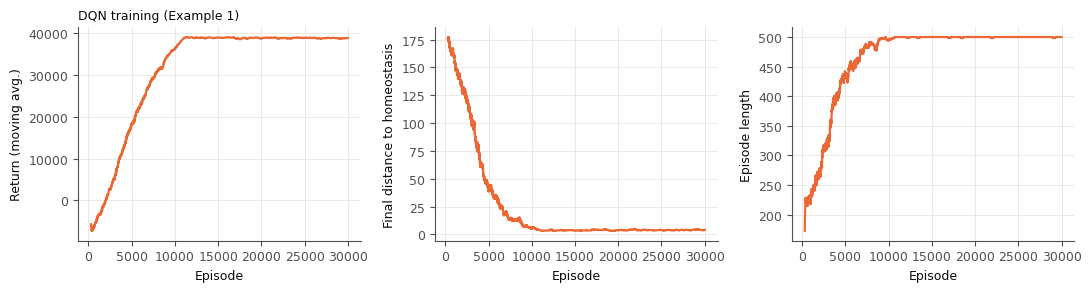

In [20]:
hist1 = dict(np.load(os.path.join(RESULTS1, "dqn_training.npz")))
print(f"{len(hist1['episode'])} episodes, {hist1['steps'][-1]:,} environment steps")
plot_training(hist1, os.path.join(RESULTS1, "dqn_training.png"), title="DQN training (Example 1)")

### 8.3 Deploy the learned growth law

The greedy policy of the trained network (with the no-growth tie-breaking of Section 6.1) is applied to the
artery under the hypertensive pressure schedule, together with the Taber & Humphrey law for comparison.

In [21]:
QUIESCENCE_TOL = 3e-3
results1 = {}

pol1 = QNetworkPolicy(agent1, env1.no_growth_action, QUIESCENCE_TOL)
results1["Deep Q network"] = simulate_iaa(artery, rl_growth_step_iaa(pol1, env1.action_table), n_steps=140, dt=0.2)

th1 = TaberHumphreyLaw(sig_tt_h=env1.s_h[0], tau_h=env1.s_h[2])
results1["Taber & Humphrey (2001)"] = simulate_iaa(artery, taber_humphrey_step_iaa(th1, 0.2), n_steps=140, dt=0.2)

for name, h in results1.items():
    print(f"{name:26s} day {h['t'][-1]:.0f}: lam_g = ({h['lam_gr'][-1]:.3f}, {h['lam_gt'][-1]:.3f}, {h['lam_gz'][-1]:.3f})  "
          f"H = {h['H_unloaded'][-1]:.3f} mm  r_i = {h['r_i'][-1]:.3f} mm  lam_ez = {h['lam_ez'][-1]:.3f}  "
          f"(s_tt, s_zz, tau_w) = ({h['sig_tt'][-1]:.1f}, {h['sig_zz'][-1]:.1f}, {h['tau_w'][-1]:.1f})")
print(f"{'experiment, day 28':26s} H = {data.unloaded_thickness_mm[-1]:.3f} mm  r_i = {data.systolic_inner_radius_mm[-1]:.3f} mm  "
      f"lam_ez = {data.in_vivo_axial_stretch[-1]:.2f}  (s_tt, s_zz, tau_w) = ({env1.s_h[0]:.1f}, {env1.s_h[1]:.1f}, {env1.s_h[2]:.1f})")

# compare with the rollout stored alongside the checkpoint (results/example1/sim_deep.npz)
ref = np.load(os.path.join(RESULTS1, "sim_deep.npz"))
worst = max(np.abs(results1["Deep Q network"][k] - ref[k]).max() for k in ref.files)
print(f"\nmax |fresh - stored| over all Example 1 DQN histories: {worst:.2e}  ->", "identical" if worst < 1e-9 else "differs (see note on near-tie actions)")

Deep Q network             day 28: lam_g = (1.510, 1.000, 1.100)  H = 0.149 mm  r_i = 0.448 mm  lam_ez = 1.645  (s_tt, s_zz, tau_w) = (227.1, 224.3, 29.7)
Taber & Humphrey (2001)    day 28: lam_g = (1.525, 1.198, 1.000)  H = 0.151 mm  r_i = 0.463 mm  lam_ez = 1.810  (s_tt, s_zz, tau_w) = (221.1, 487.8, 26.9)
experiment, day 28         H = 0.152 mm  r_i = 0.464 mm  lam_ez = 1.65  (s_tt, s_zz, tau_w) = (221.0, 226.2, 26.8)

max |fresh - stored| over all Example 1 DQN histories: 0.00e+00  -> identical


### 8.4 Figures 6-8

Panels (a)-(d) correspond to Fig. 6 of the paper (pressure, unloaded thickness, inner radius, in vivo axial
stretch), (e)-(g) to Fig. 7 (growth stretches) and (h)-(j) to Fig. 8 (stresses). Circles are the experimental
means of Bersi et al. (2017) read off the paper's figures; dashed lines are the homeostatic targets.

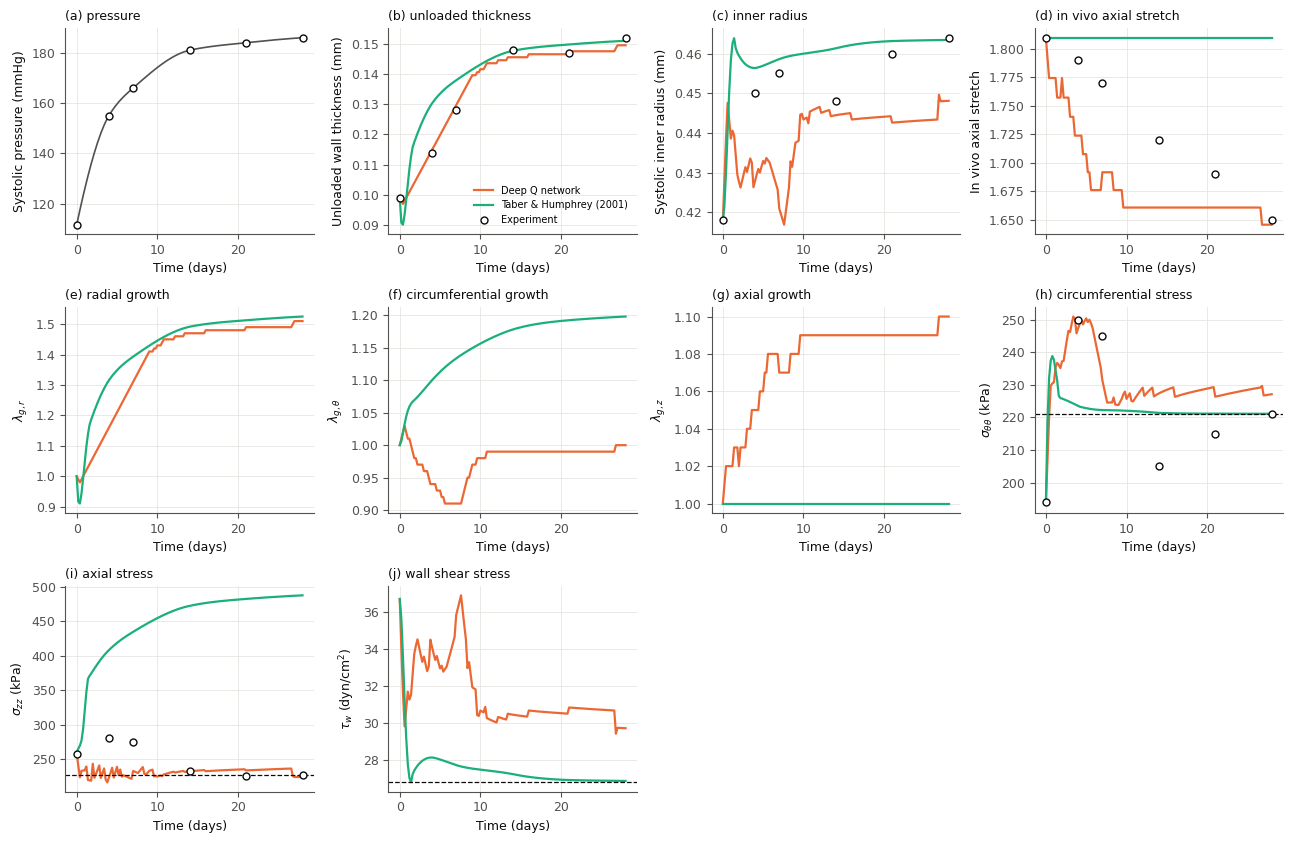

In [22]:
plot_example1(results1, data, env1.s_h, os.path.join(RESULTS1, "example1_hypertension.png"))

## 9. Example 2: growth-induced residual stress in the bi-layer human ascending aorta (Section 3.2)

Starting from a stress-free, two-layer thick-walled cylinder (media + adventitia, five Gauss points per
layer), the growth law should homogenise the transmural stresses at the layer-wise homeostatic values
without changing the loaded diameter. One agent is trained per layer at a single integration point
(Loc 3); at deployment the same network acts at all five points of its layer and the ten points grow
collaboratively for 4 days (20 steps of 0.2 day). Residual stresses are then revealed by unloading, and
the opening angle by cutting the ring (zero bending moment).

In [23]:
LAYER_NAMES = ("media", "adventitia")


def simulate_aorta(aorta, growth_step, n_steps=20, dt=0.2, lam_g0=None):
    """Collaborative growth of all integration points.

    growth_step(out, lam_g, step) -> (2, 5, 3) increments given the loaded-state dict ``out``.
    Returns dict(t, lam_g (T+1, 2, 5, 3), sig_tt/sig_zz/r (T+1, 2, 5), r_i, tau_w).
    """
    lam_g = aorta.identity_growth() if lam_g0 is None else np.array(lam_g0, float)[None]
    hist = {k: [] for k in ("t", "lam_g", "sig_rr", "sig_tt", "sig_zz", "r", "r_i", "r_out", "tau_w")}
    for n in range(n_steps + 1):
        out = aorta.loaded(lam_g)
        hist["t"].append(n * dt); hist["lam_g"].append(lam_g[0].copy())
        for k in ("sig_rr", "sig_tt", "sig_zz", "r", "r_i", "r_out", "tau_w"):
            hist[k].append(out[k][0])
        if n < n_steps:
            lam_g = lam_g + growth_step(out, lam_g, n)[None]
    return {k: np.asarray(v) for k, v in hist.items()}


def rl_growth_step_aorta(policies, action_tables):
    """policies[k](states (5,3)) -> action ids for layer k."""
    def step(out, lam_g, n):
        d = np.zeros((2, 5, 3))
        for k, pol in policies.items():
            s = np.stack([out["sig_tt"][0, k], out["sig_zz"][0, k], np.full(5, out["tau_w"][0])], 1)
            d[k] = action_tables[k][pol(s)]
        return d
    return step


def taber_humphrey_step_aorta(laws, dt):
    def step(out, lam_g, n):
        d = np.zeros((2, 5, 3))
        for k, law in enumerate(laws):
            d[k] = law.rate(out["sig_tt"][0, k], np.full(5, out["tau_w"][0])) * dt
        return d
    return step


def liu2019_step(law, aorta, mean_0, dt):
    def step(out, lam_g, n):
        mean_now = np.stack([aorta.layer_mean(out["sig_tt"])[0], aorta.layer_mean(out["sig_zz"])[0]], 0)  # (2 comp, 2 layers)
        h_t = law.homogeneity(mean_now[0], mean_0[0])
        h_z = law.homogeneity(mean_now[1], mean_0[1])
        if h_t < law.h0 and h_z < law.h0:
            return np.zeros((2, 5, 3))
        return law.rate(out["sig_rr"][0], out["sig_tt"][0], out["sig_zz"][0]) * dt
    return step


def postprocess(aorta, hist):
    """Loaded stresses, residual stresses in B_a and opening angles for the final growth state."""
    lam_g = hist["lam_g"][-1]
    loaded = aorta.loaded(lam_g)
    unl = aorta.unloaded(lam_g)
    angles = [aorta.opening_angle(lam_g, k)["alpha_deg"] for k in range(2)]
    return dict(loaded=dict(r=loaded["r"][0], sig_tt=loaded["sig_tt"][0], sig_zz=loaded["sig_zz"][0]),
                residual=dict(r=unl["r"][0], sig_tt=unl["sig_tt"][0], sig_zz=unl["sig_zz"][0]),
                opening_angle_deg=angles, r_i_loaded=float(loaded["r_i"][0]), r_out_loaded=float(loaded["r_out"][0]),
                r_i_unloaded=float(unl["r_i"]), lam_z_unloaded=float(unl["Lam"][0]))

### 9.1 Mechanics and per-layer environments

In [24]:
aorta = BilayerAorta()
envs2 = [BilayerGrowthEnv(aorta, layer=k, seed=0, admissible_starts=RETRAIN) for k in range(2)]
for k, env in enumerate(envs2):
    print(f"[{LAYER_NAMES[k]:10s}] s_h = {np.round(env.s_h, 3)}, tau_w weight = {env.dist_weights[2]}, "
          f"{env.n_actions} actions")
action_tables2 = {k: envs2[k].action_table for k in range(2)}

[media     ] s_h = [160.451 102.016   1.602], tau_w weight = 100.0, 9 actions
[adventitia] s_h = [56.067 36.733  1.602], tau_w weight = 33.3, 9 actions


**Training (disabled by default).** The checkpoints `results/example2/dqn_agent_media.pt` and
`dqn_agent_adventitia.pt` were produced by this cell: 3 600 episodes per layer with the same network and
optimiser settings as Example 1, about 8 minutes per layer on a laptop CPU.

In [25]:
agents2 = {}
for k, env in enumerate(envs2):
    name = LAYER_NAMES[k]
    cfg2 = DQNConfig(hidden=(64, 64), lr=1e-3, tau=1e-4, updates_per_step=4, eps_decay_frac=0.3, seed=0)
    if RETRAIN:
        agent = DQNAgent(3, env.n_actions, obs_offset=env.s_h, obs_scale=(50.0, 50.0, 50.0 / env.dist_weights[2]), cfg=cfg2)
        t0 = time.time()
        hist = train_dqn(env, agent, n_episodes=3600, max_steps=500, n_envs=64)
        print(f"[DQN {name}] training done in {time.time() - t0:.0f}s")
        np.savez(os.path.join(RESULTS2, f"dqn_training_{name}.npz"), **hist)
        agent.save(os.path.join(RESULTS2, f"dqn_agent_{name}.pt"))
    else:
        print(f"RETRAIN = False: loading results/example2/dqn_agent_{name}.pt")
        agent = DQNAgent.load(os.path.join(RESULTS2, f"dqn_agent_{name}.pt"))
    agents2[k] = agent

RETRAIN = False: loading results/example2/dqn_agent_media.pt
RETRAIN = False: loading results/example2/dqn_agent_adventitia.pt


### 9.2 Training curves (from the saved training histories)

media: 3604 episodes, 1,792,000 environment steps


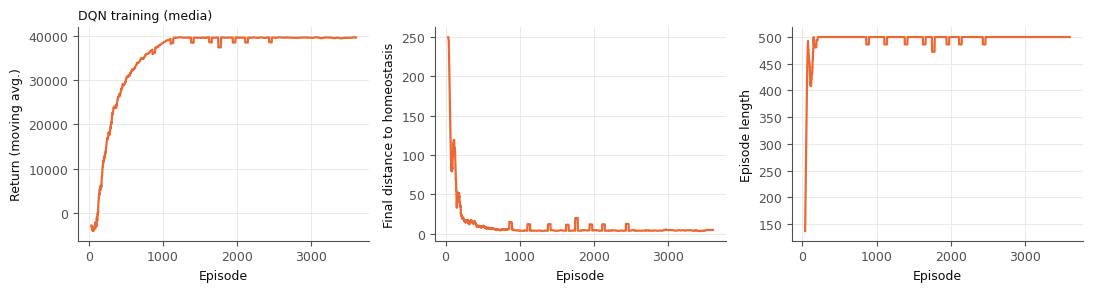

adventitia: 3600 episodes, 1,813,440 environment steps


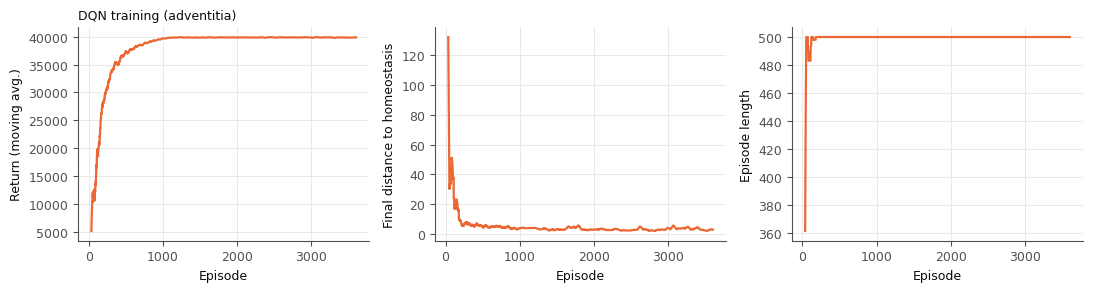

In [26]:
for k, name in enumerate(LAYER_NAMES):
    hist = dict(np.load(os.path.join(RESULTS2, f"dqn_training_{name}.npz")))
    print(f"{name}: {len(hist['episode'])} episodes, {hist['steps'][-1]:,} environment steps")
    fig = plot_training(hist, os.path.join(RESULTS2, f"dqn_training_{name}.png"), title=f"DQN training ({name})")
    display(fig)

### 9.3 Deploy the learned growth laws and the expert laws

The per-layer networks drive growth at all five Gauss points of their layer. Both expert laws are run on
the same mechanics: Taber & Humphrey with the layer-wise homeostatic stresses, and the Liu et al. (2019)
law with $\beta = 1$ and pause threshold $h_0 = 0.5$.

In [27]:
histories2 = {}

policies2 = {k: QNetworkPolicy(agents2[k], envs2[k].no_growth_action, QUIESCENCE_TOL) for k in range(2)}
histories2["Deep Q network"] = simulate_aorta(aorta, rl_growth_step_aorta(policies2, action_tables2), n_steps=20, dt=0.2)

th_laws = [TaberHumphreyLaw(sig_tt_h=envs2[k].s_h[0], tau_h=envs2[k].s_h[2]) for k in range(2)]
histories2["Taber & Humphrey (2001)"] = simulate_aorta(aorta, taber_humphrey_step_aorta(th_laws, 0.2), n_steps=20, dt=0.2)

o0 = aorta.loaded(aorta.identity_growth())
mean_0 = np.stack([aorta.layer_mean(o0["sig_tt"])[0], aorta.layer_mean(o0["sig_zz"])[0]], 0)
liu_law = Liu2019Law(h0=0.5)
histories2["Liu et al. (2019)"] = simulate_aorta(aorta, liu2019_step(liu_law, aorta, mean_0, 0.2), n_steps=20, dt=0.2)

### 9.4 Post-processing: loaded and residual stresses, opening angles

For the grown states the cut sector is almost stress free for *every* sector angle ($|\sigma| < 1.5$ kPa),
so the opening angle is very sensitive to small differences in the growth field. The absolute values
therefore differ from Table 6 of the paper even though the Taber & Humphrey growth field is reproduced to
three digits.

In [28]:
stored = json.load(open(os.path.join(RESULTS2, "summary.json")))["summary"]   # from the run that produced the checkpoints

before = postprocess(aorta, {"lam_g": aorta.identity_growth()})
loaded_plots = {"Before growth": before["loaded"]}
residual_plots, summary2 = {}, {}
for name, h in histories2.items():
    pp = postprocess(aorta, h)
    summary2[name] = dict(opening_angle_media_deg=pp["opening_angle_deg"][0],
                          opening_angle_adventitia_deg=pp["opening_angle_deg"][1],
                          r_i_loaded=pp["r_i_loaded"], r_out_loaded=pp["r_out_loaded"],
                          mean_sig_tt_media=float(aorta.layer_mean(pp["loaded"]["sig_tt"][None])[0, 0]),
                          mean_sig_tt_adventitia=float(aorta.layer_mean(pp["loaded"]["sig_tt"][None])[0, 1]),
                          final_lam_g=h["lam_g"][-1].tolist())
    loaded_plots[name] = pp["loaded"]
    residual_plots[name] = pp["residual"]

print(f"{'law':26s} {'opening angle M / A (deg)':>26s} {'loaded r_i (mm)':>16s} {'mean s_tt M / A (kPa)':>22s}")
print(f"{'before growth':26s} {before['opening_angle_deg'][0]:12.1f} / {before['opening_angle_deg'][1]:<11.1f} {before['r_i_loaded']:16.3f} "
      f"{aorta.layer_mean(before['loaded']['sig_tt'][None])[0, 0]:10.1f} / {aorta.layer_mean(before['loaded']['sig_tt'][None])[0, 1]:<9.1f}")
for name, s in summary2.items():
    print(f"{name:26s} {s['opening_angle_media_deg']:12.1f} / {s['opening_angle_adventitia_deg']:<11.1f} {s['r_i_loaded']:16.3f} "
          f"{s['mean_sig_tt_media']:10.1f} / {s['mean_sig_tt_adventitia']:<9.1f}")
print(f"{'paper (DQN / T&H / Liu)':26s} 123.0 / 71.4, 125.3 / 71.2, 40.3 / 38.6   ~7.99 (RL, T&H), larger (Liu)")


s_new, s_old = summary2["Deep Q network"], stored["Deep Q network"]
print(f"\nstored DQN result (results/example2/summary.json): opening angles {s_old['opening_angle_media_deg']:.1f} / "
      f"{s_old['opening_angle_adventitia_deg']:.1f} deg, r_i = {s_old['r_i_loaded']:.3f} mm  ->",
      "reproduced" if np.allclose([s_new['opening_angle_media_deg'], s_new['opening_angle_adventitia_deg'], s_new['r_i_loaded']],
                                  [s_old['opening_angle_media_deg'], s_old['opening_angle_adventitia_deg'], s_old['r_i_loaded']], atol=1e-6)
      else "differs (see note on near-tie actions)")

with open(os.path.join(RESULTS2, "summary.json"), "w") as f:
    json.dump({"summary": summary2}, f, indent=2)

law                         opening angle M / A (deg)  loaded r_i (mm)  mean s_tt M / A (kPa)
before growth                       0.0 / 0.0                    7.992      160.5 / 56.1     
Deep Q network                     87.3 / 37.4                   7.985      161.1 / 55.6     
Taber & Humphrey (2001)            88.9 / 76.5                   7.990      160.5 / 56.1     
Liu et al. (2019)                  55.6 / 36.7                   8.878       97.1 / 73.4     
paper (DQN / T&H / Liu)    123.0 / 71.4, 125.3 / 71.2, 40.3 / 38.6   ~7.99 (RL, T&H), larger (Liu)

stored DQN result (results/example2/summary.json): opening angles 87.3 / 37.4 deg, r_i = 7.985 mm  -> reproduced


### 9.5 Figure 11: stresses in the loaded configuration before and after growth

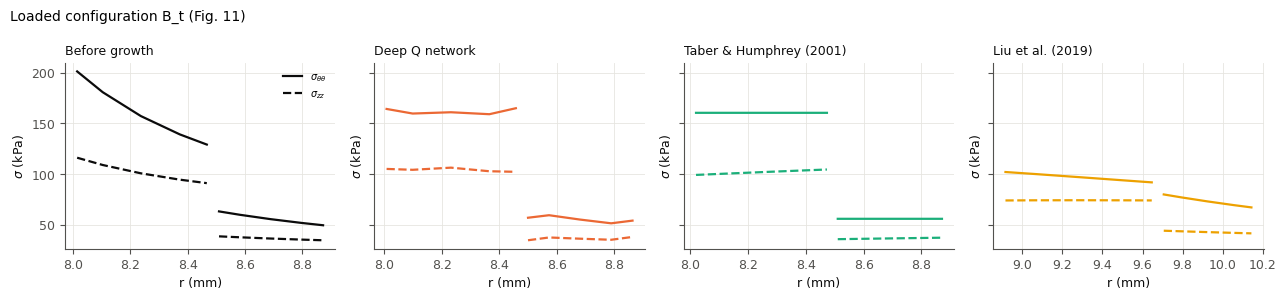

In [29]:
plot_example2_stress(loaded_plots, os.path.join(RESULTS2, "example2_loaded_stress.png"), "Loaded configuration B_t (Fig. 11)")

### 9.6 Figure 12: residual stresses in the unloaded configuration

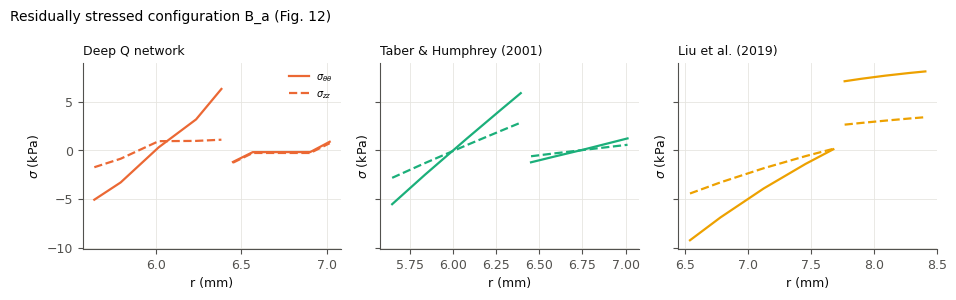

In [30]:
plot_example2_stress(residual_plots, os.path.join(RESULTS2, "example2_residual_stress.png"), "Residually stressed configuration B_a (Fig. 12)")

### 9.7 Figures 13-14: growth histories at the inner (Loc 1) and outer (Loc 5) integration points

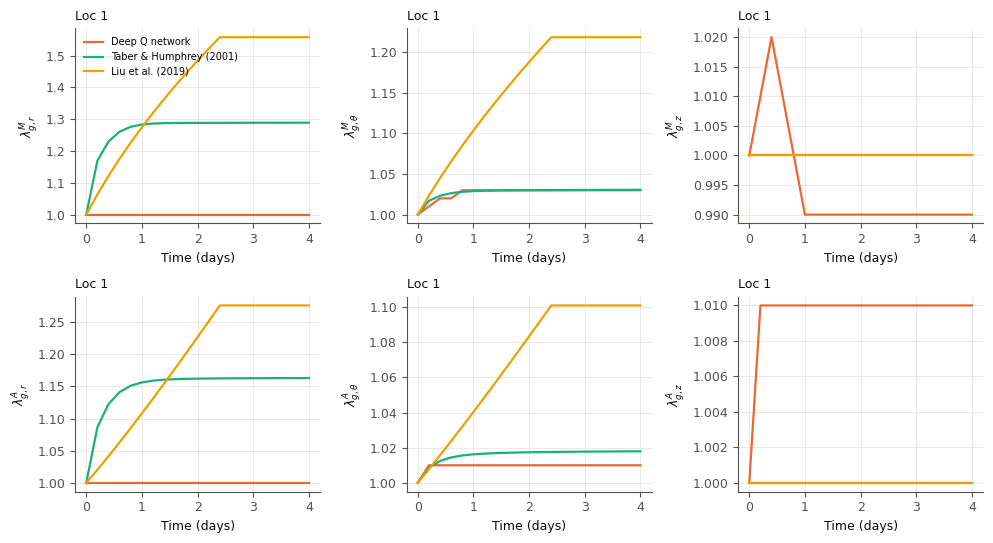

In [31]:
plot_example2_growth(histories2, 0, os.path.join(RESULTS2, "example2_growth_loc1.png"))

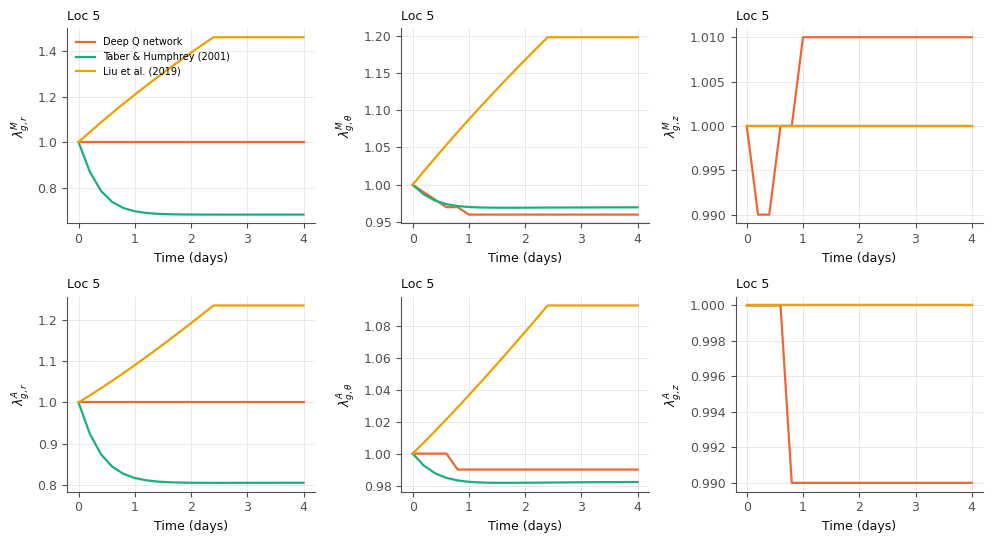

In [32]:
plot_example2_growth(histories2, 4, os.path.join(RESULTS2, "example2_growth_loc5.png"))

## 10. Sanity checks against numbers quoted in the paper

These assertions replace the former `pytest` suite: wall shear stress at the homeostatic radii (Tables 2
and 5), the day-0 state of the thin-walled artery (Figs. 6 and 8), the pre-growth state of the bi-layer
aorta (Table 5), stress-free unloading for $\mathbf{F}_g = \mathbf{I}$, and the sign of the residual stress
generated by a growth gradient.

In [33]:
# Table 2 / Table 5 homeostatic wall shear stresses
assert np.isclose(wall_shear_stress(2.8, 4.5, 0.464), 26.8, atol=0.1)
assert np.isclose(wall_shear_stress(856.5, 4.5, 7.99), 1.6035, atol=0.002)

# thin-walled IAA at day 0 (Figs. 6c, 8a, 8b)
out0 = ThinWallArtery().solve(np.ones((1, 3)), mmhg_to_kpa(111.6))
assert np.isclose(out0["r_i"][0], 0.418, atol=0.01)
assert np.isclose(out0["sig_tt"][0], 194.0, atol=6.0)
assert np.isclose(out0["sig_zz"][0], 258.0, atol=8.0)
assert np.isclose(out0["sig_tt"][0], mmhg_to_kpa(111.6) * out0["r_i"][0] / out0["h"][0], rtol=1e-8)   # Laplace
assert np.isclose(out0["lam_r"][0] * out0["lam_theta"][0] * ThinWallArtery().lam_z, 1.0, rtol=1e-10)   # incompressibility

# bi-layer aorta before growth (Table 5)
assert np.isclose(o0["r_i"][0], 7.99, atol=0.01)
m_tt, m_zz = aorta.layer_mean(o0["sig_tt"])[0], aorta.layer_mean(o0["sig_zz"])[0]
assert np.allclose(m_tt, (160.10, 55.96), rtol=0.01) and np.allclose(m_zz, (101.87, 36.70), rtol=0.01)
assert abs(o0["residual_p"][0]) < 1e-9 and -aorta.p_kPa < o0["sig_rr"][0, 0, 0] < 0.0

# unloading the ungrown vessel is stress free, a growth gradient produces residual stress
u = aorta.unloaded(aorta.identity_growth())
assert np.isclose(u["r_i"], aorta.layers[0].R_i, atol=1e-6) and np.abs(u["sig_tt"]).max() < 1e-8
assert np.isclose(aorta.opening_angle(aorta.identity_growth(), 0)["alpha_deg"], 0.0, atol=1e-6)
lam_test = aorta.identity_growth(); lam_test[0, 0, :, 1] = np.linspace(1.03, 0.97, 5)
u = aorta.unloaded(lam_test)
assert u["sig_tt"][0, 0, 0] < 0 < u["sig_tt"][0, 0, -1] and aorta.opening_angle(lam_test, 0)["alpha_deg"] > 5.0

# actions and reward
assert make_action_table(("r", "t", "z"), 0.01).shape == (27, 3) and make_action_table(("t", "z"), 0.01).shape == (9, 3)
assert np.isclose(log_reward(np.exp(150.0 / 40.0)), 0.0) and log_reward(1e-9) == 80.0 and log_reward(1e9) == -80.0
print("all checks passed")

all checks passed
